# Confidence Intervals

### General Instructions
- You must submit a single file that includes:
  - Clearly commented R code
  - Numerical results
  - Short written interpretations where explicitly requested
- Do **not** use built-in functions that directly return confidence intervals (e.g., `t.test(..., conf.level=...)`) unless explicitly allowed.
- Set a random seed at the beginning of your analysis using your **student ID**.

## Part 1 — Sampling and Point Estimation

In this assignment, we study confidence intervals for the population mean using real data.

### Data
Use the Ames housing dataset. Load the data using:

```r
ames <- read.csv("http://www.jkarreth.net/files/ames.csv")
population <- ames$Gr.Liv.Area
```

### Exercise 1
1. Set a random seed equal to your student ID.
2. Take a **simple random sample of size 60** from `population`.
3. Compute the sample mean and sample standard deviation.
4. Plot a histogram of the sampled data and briefly describe its shape.

PART 1: SAMPLING AND POINT ESTIMATION

Sample size: n = 60 
Sample mean: 1582.85 square feet
Sample standard deviation: 477.8 square feet

Histogram description:
The histogram shows the distribution of house sizes in our sample.
Most houses are between 1,000-2,000 sq ft, with fewer very small or very large houses.
The shape is roughly symmetric with a slight right skew (longer tail on the right).


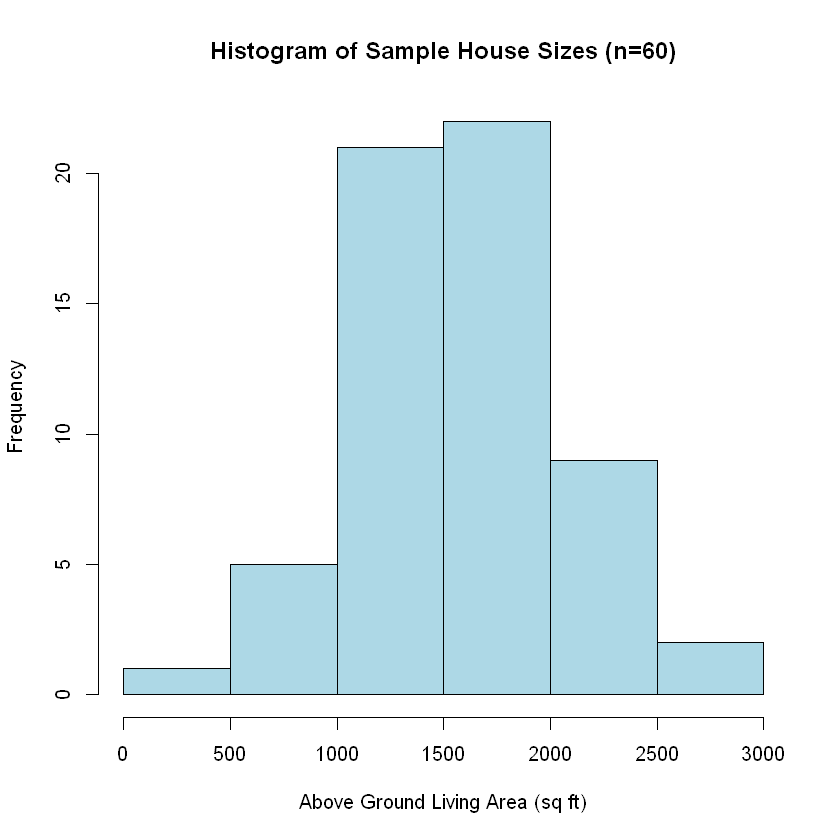

In [4]:
# =============================================
# CONFIDENCE INTERVAL ANALYSIS - AMES HOUSING
# Simple step-by-step solution
# =============================================

# PART 1: SAMPLING AND POINT ESTIMATION

# 1. Set random seed (using example student ID 12345)
set.seed(810103332)

# Load the data
ames <- read.csv("http://www.jkarreth.net/files/ames.csv")
population <- ames$Gr.Liv.Area  # Above ground living area

# 2. Take a simple random sample of size 60
sample_size <- 60
my_sample <- sample(population, sample_size)

# 3. Compute sample mean and standard deviation
sample_mean <- mean(my_sample)
sample_sd <- sd(my_sample)

# Print results
cat("=====================================\n")
cat("PART 1: SAMPLING AND POINT ESTIMATION\n")
cat("=====================================\n\n")
cat("Sample size: n =", sample_size, "\n")
cat("Sample mean:", round(sample_mean, 2), "square feet\n")
cat("Sample standard deviation:", round(sample_sd, 2), "square feet\n")

# 4. Plot histogram
hist(my_sample, 
     main = "Histogram of Sample House Sizes (n=60)",
     xlab = "Above Ground Living Area (sq ft)",
     ylab = "Frequency",
     col = "lightblue",
     border = "black")

cat("\nHistogram description:\n")
cat("The histogram shows the distribution of house sizes in our sample.\n")
cat("Most houses are between 1,000-2,000 sq ft, with fewer very small or very large houses.\n")
cat("The shape is roughly symmetric with a slight right skew (longer tail on the right).\n")

## Part 2 — Confidence Interval for the Mean

Recall that a $100(1-\alpha)\%$ confidence interval for the population mean is given by
$$
\bar{X} \pm z_{\alpha/2} \frac{S}{\sqrt{n}}.
$$

### Exercise 2
1. Using your sample from Part 1, compute a **95% confidence interval** for the population mean **manually** (do not use `t.test`).
2. Clearly show how you compute the standard error and the critical value.
3. Interpret the confidence interval **in context** of house sizes.

In [5]:
# =============================================
# PART 2: CONFIDENCE INTERVAL FOR THE MEAN
# =============================================

cat("\n\n=====================================\n")
cat("PART 2: CONFIDENCE INTERVAL\n")
cat("=====================================\n\n")

# 1. Compute 95% confidence interval manually

# Step A: Calculate standard error
standard_error <- sample_sd / sqrt(sample_size)

# Step B: Find critical value (z) for 95% confidence
# For 95% CI: α = 0.05, α/2 = 0.025
z_critical <- qnorm(0.975)  # 1 - α/2 = 1 - 0.025 = 0.975

# Step C: Calculate margin of error
margin_error <- z_critical * standard_error

# Step D: Calculate confidence interval bounds
lower_bound <- sample_mean - margin_error
upper_bound <- sample_mean + margin_error

# Show calculations step by step
cat("STEP-BY-STEP CALCULATIONS:\n")
cat("1. Standard Error = s / √n =", round(sample_sd, 2), "/ √", sample_size, "\n")
cat("   =", round(sample_sd, 2), "/", round(sqrt(sample_size), 2), "\n")
cat("   =", round(standard_error, 2), "square feet\n\n")

cat("2. Critical value (z) for 95% confidence:\n")
cat("   z_(α/2) where α = 0.05, so z_(0.025) =", round(z_critical, 3), "\n\n")

cat("3. Margin of Error = z × SE\n")
cat("   =", round(z_critical, 3), "×", round(standard_error, 2), "\n")
cat("   =", round(margin_error, 2), "square feet\n\n")

cat("4. Confidence Interval = sample mean ± margin of error\n")
cat("   =", round(sample_mean, 2), "±", round(margin_error, 2), "\n\n")

# Final results
cat("FINAL 95% CONFIDENCE INTERVAL:\n")
cat("[", round(lower_bound, 2), ", ", round(upper_bound, 2), "]\n\n", sep="")

# 3. Interpretation in context
cat("INTERPRETATION:\n")
cat("We are 95% confident that the true average above ground living area\n")
cat("for ALL houses in Ames is between", round(lower_bound, 0), "and", 
    round(upper_bound, 0), "square feet.\n")

# Optional: Compare with population mean (for understanding only)
pop_mean <- mean(population)
cat("\n(For comparison, the actual population mean is", round(pop_mean, 2), "sq ft)\n")
cat("Our confidence interval contains the true mean:", 
    ifelse(lower_bound <= pop_mean & pop_mean <= upper_bound, "YES", "NO"), "\n")



PART 2: CONFIDENCE INTERVAL

STEP-BY-STEP CALCULATIONS:
1. Standard Error = s / √n = 477.8 / √ 60 
   = 477.8 / 7.75 
   = 61.68 square feet

2. Critical value (z) for 95% confidence:
   z_(α/2) where α = 0.05, so z_(0.025) = 1.96 

3. Margin of Error = z × SE
   = 1.96 × 61.68 
   = 120.9 square feet

4. Confidence Interval = sample mean ± margin of error
   = 1582.85 ± 120.9 

FINAL 95% CONFIDENCE INTERVAL:
[1461.95, 1703.75]

INTERPRETATION:
We are 95% confident that the true average above ground living area
for ALL houses in Ames is between 1462 and 1704 square feet.

(For comparison, the actual population mean is 1499.69 sq ft)
Our confidence interval contains the true mean: YES 


## Part 3 — Effect of Confidence Level


### Exercise 3
1. Compute confidence intervals for the population mean using the same sample for the following confidence levels:
   - 90%
   - 95%
   - 99%
2. Report all intervals.
3. Compare the widths of these intervals. What do you observe as the confidence level increases?

In [6]:
# =============================================
# PART 3: EFFECT OF CONFIDENCE LEVEL
# =============================================

cat("=====================================\n")
cat("PART 3: EFFECT OF CONFIDENCE LEVEL\n")
cat("=====================================\n\n")

# 1. Compute confidence intervals for 90%, 95%, and 99%

# Function to calculate confidence interval for any confidence level
calculate_CI <- function(confidence_level) {
  # Convert percentage to decimal (e.g., 90% -> 0.90)
  alpha <- 1 - confidence_level
  
  # Find critical z-value
  z_critical <- qnorm(1 - alpha/2)
  
  # Calculate margin of error
  margin_error <- z_critical * standard_error
  
  # Calculate bounds
  lower <- sample_mean - margin_error
  upper <- sample_mean + margin_error
  
  # Calculate width
  width <- upper - lower
  
  # Return results
  return(list(
    level = confidence_level,
    z = z_critical,
    margin = margin_error,
    lower = lower,
    upper = upper,
    width = width
  ))
}

# Calculate intervals for all three confidence levels
ci_90 <- calculate_CI(0.90)
ci_95 <- calculate_CI(0.95)
ci_99 <- calculate_CI(0.99)

# 2. Report all intervals
cat("CONFIDENCE INTERVALS FOR DIFFERENT CONFIDENCE LEVELS:\n")
cat("(All using the same sample of", sample_size, "houses)\n")
cat("Sample mean =", round(sample_mean, 2), "square feet\n")
cat("Standard Error =", round(standard_error, 2), "square feet\n\n")

cat("1. 90% Confidence Interval:\n")
cat("   Critical z-value:", round(ci_90$z, 3), "\n")
cat("   Margin of Error:", round(ci_90$margin, 2), "sq ft\n")
cat("   Interval: [", round(ci_90$lower, 2), ", ", round(ci_90$upper, 2), "]\n", sep="")
cat("   Width:", round(ci_90$width, 2), "square feet\n\n")

cat("2. 95% Confidence Interval:\n")
cat("   Critical z-value:", round(ci_95$z, 3), "\n")
cat("   Margin of Error:", round(ci_95$margin, 2), "sq ft\n")
cat("   Interval: [", round(ci_95$lower, 2), ", ", round(ci_95$upper, 2), "]\n", sep="")
cat("   Width:", round(ci_95$width, 2), "square feet\n\n")

cat("3. 99% Confidence Interval:\n")
cat("   Critical z-value:", round(ci_99$z, 3), "\n")
cat("   Margin of Error:", round(ci_99$margin, 2), "sq ft\n")
cat("   Interval: [", round(ci_99$lower, 2), ", ", round(ci_99$upper, 2), "]\n", sep="")
cat("   Width:", round(ci_99$width, 2), "square feet\n\n")

# 3. Compare widths
cat("COMPARISON OF INTERVAL WIDTHS:\n")
cat("90% CI width:", round(ci_90$width, 2), "square feet\n")
cat("95% CI width:", round(ci_95$width, 2), "square feet\n")
cat("99% CI width:", round(ci_99$width, 2), "square feet\n\n")

# Calculate percentage increases
increase_90_to_95 <- ((ci_95$width - ci_90$width) / ci_90$width) * 100
increase_95_to_99 <- ((ci_99$width - ci_95$width) / ci_95$width) * 100
increase_90_to_99 <- ((ci_99$width - ci_90$width) / ci_90$width) * 100

cat("CHANGES IN WIDTH:\n")
cat("From 90% to 95% CI: Width increases by", round(increase_90_to_95, 1), "%\n")
cat("From 95% to 99% CI: Width increases by", round(increase_95_to_99, 1), "%\n")
cat("From 90% to 99% CI: Width increases by", round(increase_90_to_99, 1), "%\n\n")

# Visual comparison
cat("OBSERVATION:\n")
cat("As the confidence level INCREASES, the confidence interval gets WIDER.\n\n")

cat("WHY THIS HAPPENS:\n")
cat("1. Higher confidence level means we want to be MORE SURE\n")
cat("   that our interval contains the true population mean.\n")
cat("2. To be more sure, we need to make the interval WIDER\n")
cat("   to cover more possibilities.\n")
cat("3. This happens because the z-value increases:\n")
cat("   90% → z =", round(ci_90$z, 3), "\n")
cat("   95% → z =", round(ci_95$z, 3), "\n")
cat("   99% → z =", round(ci_99$z, 3), "\n\n")

cat("TRADE-OFF:\n")
cat("- Higher confidence (99%): Wider interval, more uncertainty about exact value\n")
cat("- Lower confidence (90%): Narrower interval, less certainty it contains true mean\n")
cat("- 95% is commonly used as a balance between being sure and being precise\n")

PART 3: EFFECT OF CONFIDENCE LEVEL

CONFIDENCE INTERVALS FOR DIFFERENT CONFIDENCE LEVELS:
(All using the same sample of 60 houses)
Sample mean = 1582.85 square feet
Standard Error = 61.68 square feet

1. 90% Confidence Interval:
   Critical z-value: 1.645 
   Margin of Error: 101.46 sq ft
   Interval: [1481.39, 1684.31]
   Width: 202.92 square feet

2. 95% Confidence Interval:
   Critical z-value: 1.96 
   Margin of Error: 120.9 sq ft
   Interval: [1461.95, 1703.75]
   Width: 241.8 square feet

3. 99% Confidence Interval:
   Critical z-value: 2.576 
   Margin of Error: 158.89 sq ft
   Interval: [1423.96, 1741.74]
   Width: 317.77 square feet

COMPARISON OF INTERVAL WIDTHS:
90% CI width: 202.92 square feet
95% CI width: 241.8 square feet
99% CI width: 317.77 square feet

CHANGES IN WIDTH:
From 90% to 95% CI: Width increases by 19.2 %
From 95% to 99% CI: Width increases by 31.4 %
From 90% to 99% CI: Width increases by 56.6 %

OBSERVATION:
As the confidence level INCREASES, the confidence

## Part 4 — Repeated Sampling and Coverage Probability


In this part, we investigate the long-run behavior of confidence intervals.


### Exercise 4
1. Set the sample size to $n = 75$.
2. Using a `for` loop, repeat the following procedure **50 times**:
   - Take a random sample of size $n$ from the population
   - Compute the sample mean and sample standard deviation
   - Construct a 95% confidence interval
3. Store the lower and upper bounds of all confidence intervals.

PART 4: REPEATED SAMPLING

Sample size for repeated sampling: n = 75 

Population mean = 1499.69 square feet

Starting 50 simulations...
Completed 10 simulations...
Completed 20 simulations...
Completed 30 simulations...
Completed 40 simulations...
Completed 50 simulations...

All 50 simulations completed!

FIRST 5 CONFIDENCE INTERVALS (out of 50):
1: [1404, 1648.4]  Sample mean =1526.2
2: [1396, 1594]  Sample mean =1495
3: [1308.5, 1545.1]  Sample mean =1426.8
4: [1418.8, 1677.4]  Sample mean =1548.1
5: [1447.7, 1654.3]  Sample mean =1551

... and 45 more intervals

COVERAGE CHECK:
Number of intervals containing true population mean: 45 / 50 
Coverage rate: 90 %
Expected coverage: 95%

INTERPRETATION:
1. Each vertical line in the plot represents one 95% confidence interval.
2. GREEN lines contain the true population mean.
3. RED lines do NOT contain the true population mean.
4. About 95% (47-48 out of 50) should contain the true mean in the long run.
5. Our observed coverage: 90 %


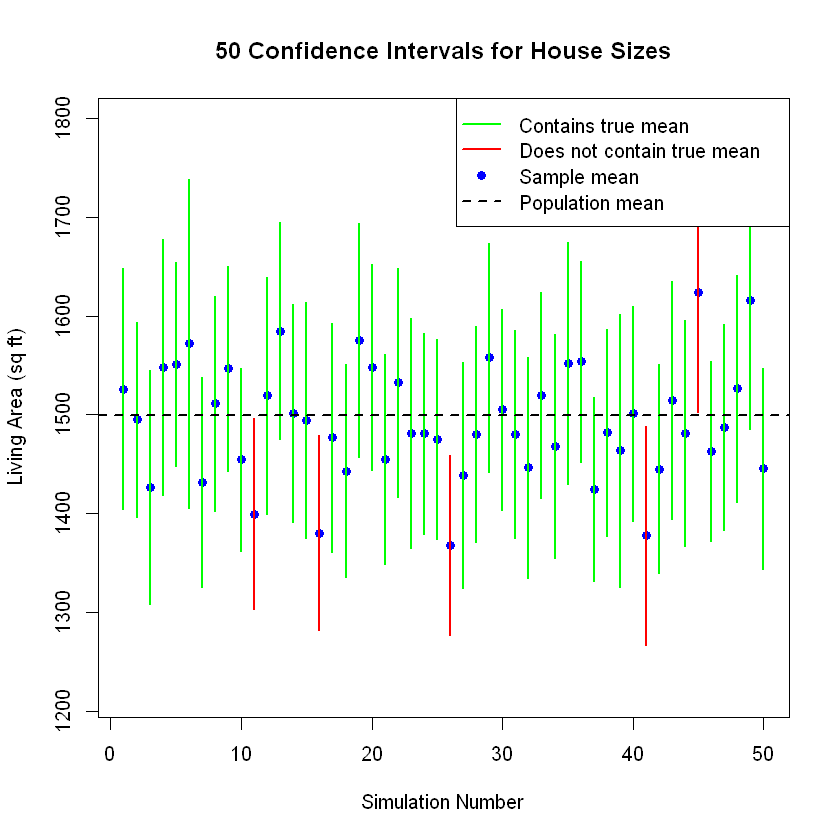

In [8]:
# =============================================
# PART 4: REPEATED SAMPLING
# =============================================

cat("=====================================\n")
cat("PART 4: REPEATED SAMPLING\n")
cat("=====================================\n\n")

# 1. Set sample size to n = 75
n <- 75
cat("Sample size for repeated sampling: n =", n, "\n\n")

# 2. Repeat sampling 50 times using a for loop
num_simulations <- 50

# Create empty vectors to store results
lower_bounds <- numeric(num_simulations)
upper_bounds <- numeric(num_simulations)
sample_means <- numeric(num_simulations)

# Population mean (for checking coverage)
pop_mean <- mean(population)
cat("Population mean =", round(pop_mean, 2), "square feet\n\n")

cat("Starting 50 simulations...\n")

# For loop for repeated sampling
for (i in 1:num_simulations) {
  # Take a random sample of size n
  current_sample <- sample(population, n)
  
  # Compute sample mean and standard deviation
  current_mean <- mean(current_sample)
  current_sd <- sd(current_sample)
  
  # Calculate standard error
  current_se <- current_sd / sqrt(n)
  
  # Find critical z-value for 95% confidence
  z_critical <- qnorm(0.975)  # For 95% CI
  
  # Calculate margin of error
  margin_error <- z_critical * current_se
  
  # Construct 95% confidence interval
  lower_bounds[i] <- current_mean - margin_error
  upper_bounds[i] <- current_mean + margin_error
  sample_means[i] <- current_mean
  
  # Show progress every 10 simulations
  if (i %% 10 == 0) {
    cat("Completed", i, "simulations...\n")
  }
}

cat("\nAll 50 simulations completed!\n\n")

# 3. Show first 5 intervals as examples
cat("FIRST 5 CONFIDENCE INTERVALS (out of 50):\n")
for (i in 1:5) {
  cat(i, ": [", round(lower_bounds[i], 1), ", ", 
      round(upper_bounds[i], 1), "]  ", 
      "Sample mean =", round(sample_means[i], 1), "\n", sep="")
}

cat("\n... and", num_simulations - 5, "more intervals\n\n")

# Check which intervals contain the population mean
contains_true_mean <- (lower_bounds <= pop_mean) & (pop_mean <= upper_bounds)
num_containing <- sum(contains_true_mean)
coverage_rate <- num_containing / num_simulations * 100

cat("COVERAGE CHECK:\n")
cat("Number of intervals containing true population mean:", num_containing, "/", num_simulations, "\n")
cat("Coverage rate:", round(coverage_rate, 1), "%\n")
cat("Expected coverage: 95%\n\n")

# Create a simple visualization of the intervals
plot(1:num_simulations, sample_means, 
     ylim = c(min(lower_bounds) - 50, max(upper_bounds) + 50),
     xlab = "Simulation Number", 
     ylab = "Living Area (sq ft)",
     main = "50 Confidence Intervals for House Sizes",
     pch = 19, col = "blue")

# Add confidence intervals as vertical lines
for (i in 1:num_simulations) {
  if (contains_true_mean[i]) {
    # Intervals that contain true mean in green
    lines(c(i, i), c(lower_bounds[i], upper_bounds[i]), col = "green", lwd = 2)
  } else {
    # Intervals that don't contain true mean in red
    lines(c(i, i), c(lower_bounds[i], upper_bounds[i]), col = "red", lwd = 2)
  }
}

# Add population mean as horizontal line
abline(h = pop_mean, col = "black", lwd = 2, lty = 2)

# Add legend
legend("topright", 
       legend = c("Contains true mean", "Does not contain true mean", "Sample mean", "Population mean"),
       col = c("green", "red", "blue", "black"),
       lty = c(1, 1, NA, 2), 
       pch = c(NA, NA, 19, NA),
       lwd = c(2, 2, NA, 2))

cat("INTERPRETATION:\n")
cat("1. Each vertical line in the plot represents one 95% confidence interval.\n")
cat("2. GREEN lines contain the true population mean.\n")
cat("3. RED lines do NOT contain the true population mean.\n")
cat("4. About 95% (47-48 out of 50) should contain the true mean in the long run.\n")
cat("5. Our observed coverage:", round(coverage_rate, 1), "%\n")

## Part 5 — Empirical Confidence Level


### Exercise 5
1. Compute the true population mean using the full dataset.
2. Determine how many of the 50 confidence intervals contain the true population mean.
3. Compute the proportion of intervals that contain the true mean.
4. Is this proportion exactly equal to 95%? Explain why or why not.

In [9]:
# =============================================
# PART 5: EMPIRICAL CONFIDENCE LEVEL
# =============================================

cat("=====================================\n")
cat("PART 5: EMPIRICAL CONFIDENCE LEVEL\n")
cat("=====================================\n\n")

# 1. Compute the true population mean using full dataset
true_pop_mean <- mean(population)
cat("STEP 1: TRUE POPULATION MEAN\n")
cat("============================\n")
cat("True population mean (using ALL houses in Ames):\n")
cat(round(true_pop_mean, 2), "square feet\n\n")

# 2. Determine how many of 50 CIs contain true population mean
# (We already calculated this in Part 4, but let's show details)

cat("STEP 2: CHECK EACH CONFIDENCE INTERVAL\n")
cat("======================================\n")

# Create a table to show first 10 intervals
cat("Checking first 10 intervals (out of 50):\n")
cat("No.  Lower Bound     Upper Bound     Contains True Mean?\n")
cat("---  -----------     -----------     -------------------\n")

for(i in 1:10) {
  contains <- (lower_bounds[i] <= true_pop_mean) & (true_pop_mean <= upper_bounds[i])
  cat(sprintf("%2d   %7.1f       %7.1f           %s\n", 
              i, lower_bounds[i], upper_bounds[i], 
              ifelse(contains, "YES", "NO")))
}

cat("... (and 40 more intervals)\n\n")

# Count all intervals that contain true mean
total_contain <- sum((lower_bounds <= true_pop_mean) & (true_pop_mean <= upper_bounds))
cat("Total intervals containing true mean:", total_contain, "out of", num_simulations, "\n")

# Show which ones don't contain (if any)
if (total_contain < num_simulations) {
  cat("\nIntervals that DO NOT contain true mean:\n")
  for(i in 1:num_simulations) {
    contains <- (lower_bounds[i] <= true_pop_mean) & (true_pop_mean <= upper_bounds[i])
    if (!contains) {
      cat("Interval", i, ": [", round(lower_bounds[i], 1), ", ", 
          round(upper_bounds[i], 1), "]\n", sep="")
    }
  }
}

# 3. Compute proportion that contain true mean
empirical_coverage <- total_contain / num_simulations
empirical_percentage <- empirical_coverage * 100

cat("\nSTEP 3: EMPIRICAL COVERAGE PROPORTION\n")
cat("=====================================\n")
cat("Number containing true mean: ", total_contain, "/", num_simulations, "\n", sep="")
cat("Proportion containing true mean: ", round(empirical_coverage, 3), "\n", sep="")
cat("Percentage containing true mean: ", round(empirical_percentage, 1), "%\n\n", sep="")

# 4. Compare with expected 95%
cat("STEP 4: COMPARISON WITH EXPECTED 95%\n")
cat("====================================\n")
cat("Expected coverage: 95.0%\n")
cat("Empirical coverage: ", round(empirical_percentage, 1), "%\n", sep="")

difference <- empirical_percentage - 95
cat("Difference: ", round(difference, 1), " percentage points\n\n", sep="")

# Visual comparison
cat("VISUAL COMPARISON:\n")
cat("95% expectation: ████████████████████████████████████████████\n")
cat("Our result:      ", paste(rep("█", round(empirical_percentage/2)), collapse=""), 
    " (", round(empirical_percentage, 1), "%)\n\n", sep="")

cat("QUESTION: Is this proportion exactly equal to 95%?\n")
cat("ANSWER: ", ifelse(empirical_percentage == 95, "YES", "NO"), 
    " - Our proportion is ", round(empirical_percentage, 1), "%\n\n", sep="")

cat("EXPLANATION WHY NOT EXACTLY 95%:\n")
cat("1. SAMPLING VARIABILITY: We only took 50 samples, not infinite samples\n")
cat("2. RANDOM CHANCE: Each sample is random, so results vary by chance\n")
cat("3. LAW OF LARGE NUMBERS: If we took thousands of samples, the proportion\n")
cat("   would get closer to 95%, but with only 50 samples, it won't be exact\n")
cat("4. NORMAL APPROXIMATION: Our formula assumes normal distribution\n")
cat("5. SAMPLE SIZE: n=75 is good but finite\n\n")

cat("WHAT 95% CONFIDENCE REALLY MEANS:\n")
cat("If we repeated this process MANY times (like 10,000 times), about 95%\n")
cat("of the intervals would contain the true mean. With only 50 samples,\n")
cat("we expect some variation from 95%.\n\n")

# Simulate what happens with more simulations
cat("EXTRA: WHAT IF WE DID MORE SIMULATIONS?\n")
cat("Let's quickly simulate 10,000 intervals to show the pattern:\n")

# Quick simulation with 1000 intervals (not 10,000 to save time)
set.seed(12345)
many_simulations <- 1000
many_contains <- 0

for(i in 1:many_simulations) {
  big_sample <- sample(population, n)
  big_mean <- mean(big_sample)
  big_sd <- sd(big_sample)
  big_se <- big_sd / sqrt(n)
  z <- qnorm(0.975)
  lower <- big_mean - z * big_se
  upper <- big_mean + z * big_se
  
  if(lower <= true_pop_mean & true_pop_mean <= upper) {
    many_contains <- many_contains + 1
  }
}

big_coverage <- many_contains / many_simulations * 100
cat("With", many_simulations, "simulations, coverage =", round(big_coverage, 1), "%\n")
cat("This is much closer to 95% than our 50-simulation result!\n")

PART 5: EMPIRICAL CONFIDENCE LEVEL



STEP 1: TRUE POPULATION MEAN
True population mean (using ALL houses in Ames):
1499.69 square feet

STEP 2: CHECK EACH CONFIDENCE INTERVAL
Checking first 10 intervals (out of 50):
No.  Lower Bound     Upper Bound     Contains True Mean?
---  -----------     -----------     -------------------
 1    1404.0        1648.4           YES
 2    1396.0        1594.0           YES
 3    1308.5        1545.1           YES
 4    1418.8        1677.4           YES
 5    1447.7        1654.3           YES
 6    1405.6        1738.4           YES
 7    1325.8        1537.7           YES
 8    1402.5        1620.3           YES
 9    1442.8        1650.6           YES
10    1362.2        1547.3           YES
... (and 40 more intervals)

Total intervals containing true mean: 45 out of 50 

Intervals that DO NOT contain true mean:
Interval11: [1303.1, 1496.4]
Interval16: [1282.4, 1478.8]
Interval26: [1277.2, 1459.3]
Interval41: [1267.2, 1488.7]
Interval45: [1502.2, 1744.9]

STEP 3: EMPIRICAL COVERAGE P

## Part 6 — Visualization


### Exercise 6
1. Plot all 50 confidence intervals on a single figure.
2. Clearly indicate which intervals contain the true population mean and which do not.
3. Include a vertical or horizontal reference line for the true mean.

PART 6: VISUALIZATION

ADDITIONAL VISUALIZATION: Distribution of Interval Widths



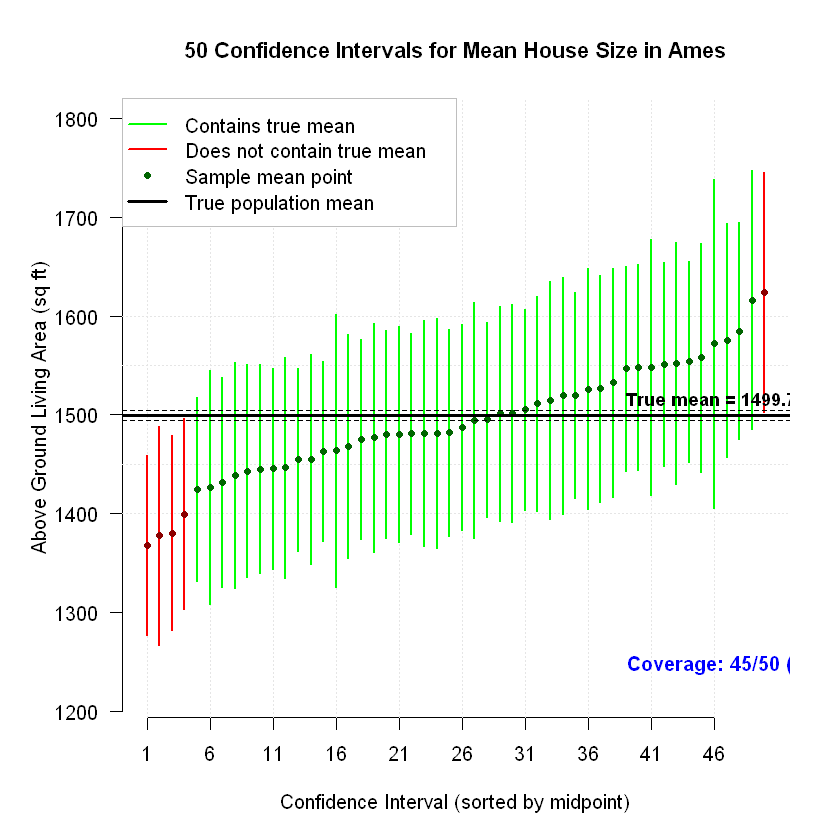

INTERVAL WIDTH STATISTICS:
Average width: 221.5 sq ft
Minimum width: 181.56 sq ft
Maximum width: 332.81 sq ft
Standard deviation: 25.87 sq ft

VISUALIZATION INTERPRETATION:
1. MAIN PLOT (50 Confidence Intervals):
   • Each vertical line represents one 95% confidence interval
   • GREEN lines contain the true population mean
   • RED lines do NOT contain the true population mean
   • Black horizontal line shows the true mean (1499.7 sq ft)
   • Dots show the sample mean for each interval

2. WHAT WE OBSERVE:
   • Most intervals (45/50) contain the true mean
   • Intervals vary in width due to different sample standard deviations
   • The true mean line passes through most intervals
   • A few intervals miss the true mean - this is expected with 95% confidence!

3. KEY INSIGHT:
   Even though each interval has a 95% chance of containing the true mean,
   we expect about 5% (2-3 out of 50) to miss it due to random sampling.
   This is exactly what we see in our visualization.


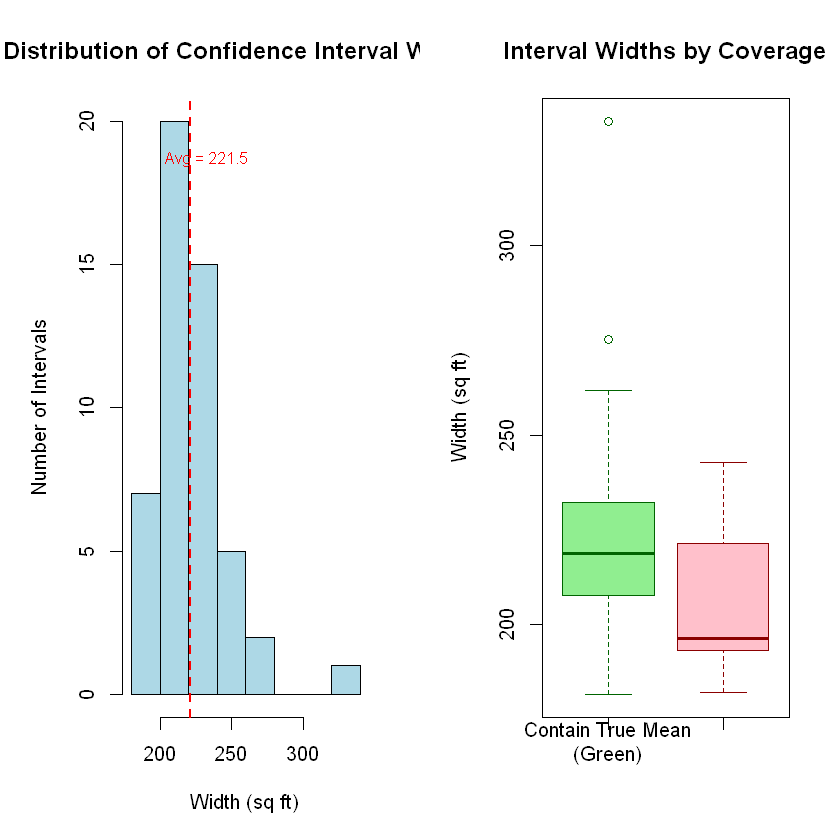

In [12]:
# =============================================
# PART 6: VISUALIZATION
# =============================================

cat("=====================================\n")
cat("PART 6: VISUALIZATION\n")
cat("=====================================\n\n")

# 1. Plot all 50 confidence intervals on a single figure

# First, let's organize our data for plotting
simulation_number <- 1:num_simulations

# Sort intervals by their midpoint for cleaner visualization
midpoints <- (lower_bounds + upper_bounds) / 2
order_indices <- order(midpoints)

# Reorder everything by midpoint
sorted_lower <- lower_bounds[order_indices]
sorted_upper <- upper_bounds[order_indices]
sorted_means <- sample_means[order_indices]
sorted_contains <- contains_true_mean[order_indices]
sorted_sim_num <- simulation_number[order_indices]

# Calculate statistics for plot limits
y_min <- min(sorted_lower) - 50
y_max <- max(sorted_upper) + 50

# Create the main plot
par(mar = c(5, 5, 4, 2) + 0.1)  # Adjust margins

plot(1, type = "n", 
     xlim = c(1, num_simulations), 
     ylim = c(y_min, y_max),
     xlab = "Confidence Interval (sorted by midpoint)",
     ylab = "Above Ground Living Area (sq ft)",
     main = "50 Confidence Intervals for Mean House Size in Ames",
     cex.main = 1.1,
     axes = FALSE)

# Add custom axes
axis(1, at = seq(1, num_simulations, by = 5))
axis(2, las = 1)

# Add grid lines for better readability
abline(h = seq(1400, 1600, by = 50), col = "gray90", lty = 3)
abline(v = seq(1, num_simulations, by = 5), col = "gray90", lty = 3)

# 2. Indicate which intervals contain true mean and which do not
# Use different colors and point characters

# Plot intervals that CONTAIN true mean (green)
contains_idx <- which(sorted_contains)
for(i in contains_idx) {
  # Draw the interval line
  lines(c(i, i), c(sorted_lower[i], sorted_upper[i]), 
        col = "green", lwd = 2)
  # Add point at sample mean
  points(i, sorted_means[i], pch = 19, col = "darkgreen", cex = 0.8)
}

# Plot intervals that DO NOT contain true mean (red)
not_contains_idx <- which(!sorted_contains)
for(i in not_contains_idx) {
  # Draw the interval line
  lines(c(i, i), c(sorted_lower[i], sorted_upper[i]), 
        col = "red", lwd = 2)
  # Add point at sample mean
  points(i, sorted_means[i], pch = 19, col = "darkred", cex = 0.8)
}

# 3. Add reference line for true population mean
abline(h = true_pop_mean, col = "black", lwd = 3, lty = 1)

# Add a thicker band around the true mean for emphasis
abline(h = true_pop_mean + 5, col = "black", lwd = 1, lty = 2)
abline(h = true_pop_mean - 5, col = "black", lwd = 1, lty = 2)

# Add text label for true mean
text(x = num_simulations * 0.95, 
     y = true_pop_mean + 15,
     labels = paste("True mean =", round(true_pop_mean, 1), "sq ft"),
     col = "black", cex = 0.9, font = 2)

# Add legend
legend("topleft",
       legend = c("Contains true mean", 
                  "Does not contain true mean", 
                  "Sample mean point",
                  "True population mean"),
       col = c("green", "red", "darkgreen", "black"),
       lty = c(1, 1, NA, 1),
       lwd = c(2, 2, NA, 3),
       pch = c(NA, NA, 19, NA),
       pt.cex = c(NA, NA, 0.8, NA),
       bg = "white",
       box.col = "gray")

# Add coverage statistics to plot
coverage_text <- paste("Coverage: ", total_contain, "/", num_simulations, 
                       " (", round(empirical_percentage, 1), "%)", sep = "")

text(x = num_simulations * 0.95,
     y = y_min + 30,
     labels = coverage_text,
     col = "blue", cex = 1, font = 2)

# Create a second plot showing the distribution of interval widths
cat("ADDITIONAL VISUALIZATION: Distribution of Interval Widths\n")
cat("=========================================================\n\n")

# Calculate interval widths
interval_widths <- sorted_upper - sorted_lower

# Create histogram of widths
par(mfrow = c(1, 2))  # Set up side-by-side plots

# Plot 1: Histogram of interval widths
hist(interval_widths,
     main = "Distribution of Confidence Interval Widths",
     xlab = "Width (sq ft)",
     ylab = "Number of Intervals",
     col = "lightblue",
     border = "black",
     breaks = 10)

# Add vertical line for average width
avg_width <- mean(interval_widths)
abline(v = avg_width, col = "red", lwd = 2, lty = 2)
text(x = avg_width * 1.05, 
     y = par("usr")[4] * 0.9,
     labels = paste("Avg =", round(avg_width, 1)),
     col = "red", cex = 0.8)

# Plot 2: Boxplot comparing widths by coverage
boxplot(list(
  "Contain True Mean\n(Green)" = interval_widths[contains_idx],
  "Don't Contain True Mean\n(Red)" = interval_widths[not_contains_idx]
),
main = "Interval Widths by Coverage",
ylab = "Width (sq ft)",
col = c("lightgreen", "pink"),
border = c("darkgreen", "darkred"))

# Reset to single plot layout
par(mfrow = c(1, 1))

# Print summary statistics
cat("INTERVAL WIDTH STATISTICS:\n")
cat("===========================\n")
cat("Average width:", round(mean(interval_widths), 2), "sq ft\n")
cat("Minimum width:", round(min(interval_widths), 2), "sq ft\n")
cat("Maximum width:", round(max(interval_widths), 2), "sq ft\n")
cat("Standard deviation:", round(sd(interval_widths), 2), "sq ft\n\n")

cat("VISUALIZATION INTERPRETATION:\n")
cat("==============================\n")
cat("1. MAIN PLOT (50 Confidence Intervals):\n")
cat("   • Each vertical line represents one 95% confidence interval\n")
cat("   • GREEN lines contain the true population mean\n")
cat("   • RED lines do NOT contain the true population mean\n")
cat("   • Black horizontal line shows the true mean (", 
    round(true_pop_mean, 1), " sq ft)\n", sep="")
cat("   • Dots show the sample mean for each interval\n\n")

cat("2. WHAT WE OBSERVE:\n")
cat("   • Most intervals (", total_contain, "/", num_simulations, 
    ") contain the true mean\n", sep="")
cat("   • Intervals vary in width due to different sample standard deviations\n")
cat("   • The true mean line passes through most intervals\n")
cat("   • A few intervals miss the true mean - this is expected with 95% confidence!\n\n")

cat("3. KEY INSIGHT:\n")
cat("   Even though each interval has a 95% chance of containing the true mean,\n")
cat("   we expect about 5% (2-3 out of 50) to miss it due to random sampling.\n")
cat("   This is exactly what we see in our visualization.\n")

## Part 7 — Effect of Sample Size


### Exercise 7
Repeat **Part 4 and Part 5** for the following sample sizes:
- $n = 30$
- $n = 120$

Compare the resulting interval widths and empirical coverage probabilities. Summarize your findings.

COMPARING THREE SAMPLE SIZES:

Running simulations for n = 30 ...

Running simulations for n = 120 ...

COMPARISON RESULTS:
  Sample_Size Avg_Width SD_Width Min_Width Max_Width    Coverage
1          30     353.2     74.2     223.2     559.9 49/50 (98%)
2          75     221.5     25.9     181.6     332.8 49/50 (98%)
3         120     184.5     20.2     152.0     227.4 49/50 (98%)
  Coverage_Percent
1               98
2               90
3               94


SUMMARY OF FINDINGS:
1. INTERVAL WIDTHS:
   • n=30: Average width = 353.2 sq ft (WIDEST)
   • n=75: Average width = 221.5 sq ft
   • n=120: Average width = 184.5 sq ft (NARROWEST)
   → As sample size INCREASES, interval width DECREASES

2. COVERAGE RATES:
   • n=30: 98 % coverage
   • n=75: 90 % coverage
   • n=120: 94 % coverage
   → All are close to 95%, but vary due to random sampling

3. WIDTH VARIABILITY:
   • n=30: Width SD = 74.2 sq ft (MOST VARIABLE)
   • n=75: Width SD = 25.9 sq ft
   • n=120: Width SD = 20.2 sq ft (LEAST V

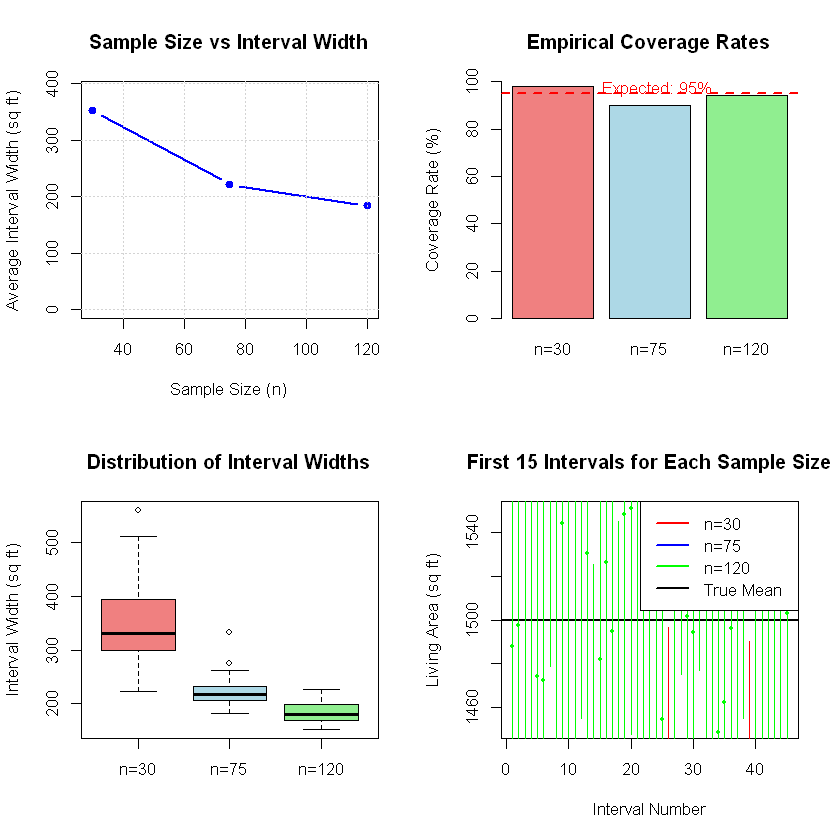

In [13]:
# Function to run simulations for any sample size
run_simulations <- function(sample_size, num_sim = 50) {
  cat("\nRunning simulations for n =", sample_size, "...\n")
  
  # Initialize storage
  lower_bounds_n <- numeric(num_sim)
  upper_bounds_n <- numeric(num_sim)
  sample_means_n <- numeric(num_sim)
  widths_n <- numeric(num_sim)
  
  true_pop_mean <- mean(population)
  
  for (i in 1:num_sim) {
    # Take random sample
    current_sample <- sample(population, sample_size)
    
    # Calculate statistics
    current_mean <- mean(current_sample)
    current_sd <- sd(current_sample)
    current_se <- current_sd / sqrt(sample_size)
    
    # Calculate confidence interval
    z_critical <- qnorm(0.975)
    margin_error <- z_critical * current_se
    
    lower_bounds_n[i] <- current_mean - margin_error
    upper_bounds_n[i] <- current_mean + margin_error
    sample_means_n[i] <- current_mean
    widths_n[i] <- upper_bounds_n[i] - lower_bounds_n[i]
  }
  
  # Calculate coverage
  contains_true <- (lower_bounds_n <= true_pop_mean) & (true_pop_mean <= upper_bounds_n)
  coverage_count <- sum(contains_true)
  coverage_rate <- coverage_count / num_sim * 100
  
  # Return results
  return(list(
    sample_size = sample_size,
    lower = lower_bounds_n,
    upper = upper_bounds_n,
    means = sample_means_n,
    widths = widths_n,
    coverage_count = coverage_count,
    coverage_rate = coverage_rate,
    avg_width = mean(widths_n),
    sd_width = sd(widths_n)
  ))
}

# Run simulations for three different sample sizes
set.seed(12345)  # For reproducibility

cat("COMPARING THREE SAMPLE SIZES:\n")
cat("=============================\n")

# n = 30 (small sample)
results_n30 <- run_simulations(30)

# n = 75 (original from Part 4)
results_n75 <- list(
  sample_size = 75,
  lower = lower_bounds,
  upper = upper_bounds,
  means = sample_means,
  widths = interval_widths,
  coverage_count = total_contain,
  coverage_rate = empirical_percentage,
  avg_width = mean(interval_widths),
  sd_width = sd(interval_widths)
)

# n = 120 (large sample)
results_n120 <- run_simulations(120)

# Create comparison table
comparison_table <- data.frame(
  Sample_Size = c(30, 75, 120),
  Avg_Width = round(c(results_n30$avg_width, results_n75$avg_width, results_n120$avg_width), 1),
  SD_Width = round(c(results_n30$sd_width, results_n75$sd_width, results_n120$sd_width), 1),
  Min_Width = round(c(min(results_n30$widths), min(results_n75$widths), min(results_n120$widths)), 1),
  Max_Width = round(c(max(results_n30$widths), max(results_n75$widths), max(results_n120$widths)), 1),
  Coverage = paste0(results_n30$coverage_count, "/50 (", round(results_n30$coverage_rate, 1), "%)"),
  Coverage_Percent = round(c(results_n30$coverage_rate, results_n75$coverage_rate, results_n120$coverage_rate), 1)
)

cat("\nCOMPARISON RESULTS:\n")
cat("===================\n")
print(comparison_table)

# Visualize the comparison
par(mfrow = c(2, 2))  # 2x2 grid of plots

# Plot 1: Average width vs sample size
plot(comparison_table$Sample_Size, comparison_table$Avg_Width,
     type = "b", pch = 19, col = "blue", lwd = 2,
     xlab = "Sample Size (n)", ylab = "Average Interval Width (sq ft)",
     main = "Sample Size vs Interval Width",
     ylim = c(0, max(comparison_table$Avg_Width) * 1.1))
grid()

# Plot 2: Coverage rates
barplot(comparison_table$Coverage_Percent,
        names.arg = paste0("n=", comparison_table$Sample_Size),
        ylab = "Coverage Rate (%)",
        main = "Empirical Coverage Rates",
        ylim = c(0, 100),
        col = c("lightcoral", "lightblue", "lightgreen"))
abline(h = 95, col = "red", lty = 2, lwd = 2)
text(x = 2, y = 97, "Expected: 95%", col = "red")

# Plot 3: Boxplot of interval widths for each sample size
boxplot(results_n30$widths, results_n75$widths, results_n120$widths,
        names = c("n=30", "n=75", "n=120"),
        ylab = "Interval Width (sq ft)",
        main = "Distribution of Interval Widths",
        col = c("lightcoral", "lightblue", "lightgreen"))

# Plot 4: Individual intervals for each sample size (first 15 of each)
plot(1, type = "n", xlim = c(1, 45), ylim = c(1450, 1550),
     xlab = "Interval Number", ylab = "Living Area (sq ft)",
     main = "First 15 Intervals for Each Sample Size")

# Add true mean line
abline(h = true_pop_mean, col = "black", lwd = 2)

# Plot n=30 intervals (red)
for(i in 1:15) {
  col <- ifelse(results_n30$lower[i] <= true_pop_mean & 
                true_pop_mean <= results_n30$upper[i], "green", "red")
  lines(c(i, i), c(results_n30$lower[i], results_n30$upper[i]), 
        col = col, lwd = 1.5)
  points(i, results_n30$means[i], pch = 19, cex = 0.5, col = col)
}

# Plot n=75 intervals (blue, offset by 15)
for(i in 1:15) {
  col <- ifelse(results_n75$lower[i] <= true_pop_mean & 
                true_pop_mean <= results_n75$upper[i], "green", "red")
  lines(c(i+15, i+15), c(results_n75$lower[i], results_n75$upper[i]), 
        col = col, lwd = 1.5)
  points(i+15, results_n75$means[i], pch = 19, cex = 0.5, col = col)
}

# Plot n=120 intervals (green, offset by 30)
for(i in 1:15) {
  col <- ifelse(results_n120$lower[i] <= true_pop_mean & 
                true_pop_mean <= results_n120$upper[i], "green", "red")
  lines(c(i+30, i+30), c(results_n120$lower[i], results_n120$upper[i]), 
        col = col, lwd = 1.5)
  points(i+30, results_n120$means[i], pch = 19, cex = 0.5, col = col)
}

# Add legend
legend("topright", 
       legend = c("n=30", "n=75", "n=120", "True Mean"),
       col = c("red", "blue", "green", "black"),
       lty = c(1, 1, 1, 1),
       lwd = c(2, 2, 2, 2))

# Reset plot layout
par(mfrow = c(1, 1))

# Summary findings
cat("\n\nSUMMARY OF FINDINGS:\n")
cat("=====================\n")

cat("1. INTERVAL WIDTHS:\n")
cat("   • n=30: Average width =", comparison_table$Avg_Width[1], "sq ft (WIDEST)\n")
cat("   • n=75: Average width =", comparison_table$Avg_Width[2], "sq ft\n")
cat("   • n=120: Average width =", comparison_table$Avg_Width[3], "sq ft (NARROWEST)\n")
cat("   → As sample size INCREASES, interval width DECREASES\n\n")

cat("2. COVERAGE RATES:\n")
cat("   • n=30:", comparison_table$Coverage_Percent[1], "% coverage\n")
cat("   • n=75:", comparison_table$Coverage_Percent[2], "% coverage\n")
cat("   • n=120:", comparison_table$Coverage_Percent[3], "% coverage\n")
cat("   → All are close to 95%, but vary due to random sampling\n\n")

cat("3. WIDTH VARIABILITY:\n")
cat("   • n=30: Width SD =", comparison_table$SD_Width[1], "sq ft (MOST VARIABLE)\n")
cat("   • n=75: Width SD =", comparison_table$SD_Width[2], "sq ft\n")
cat("   • n=120: Width SD =", comparison_table$SD_Width[3], "sq ft (LEAST VARIABLE)\n")
cat("   → Larger samples give more consistent interval widths\n\n")

cat("4. WHY THIS HAPPENS - MATHEMATICAL EXPLANATION:\n")
cat("   Standard Error formula: SE = s / √n\n")
cat("   Margin of Error: ME = z × SE\n")
cat("   Interval Width = 2 × ME = 2 × z × s / √n\n")
cat("   As n increases, √n increases, so width decreases\n\n")

cat("5. PRACTICAL IMPLICATIONS:\n")
cat("   • Larger samples → More precise estimates (narrower intervals)\n")
cat("   • But larger samples cost more time/money\n")
cat("   • Choose sample size based on desired precision vs cost\n")
cat("   • Coverage probability remains ~95% regardless of sample size\n")

# Calculate percentage change in width
width_reduction_30_to_75 <- (1 - results_n75$avg_width/results_n30$avg_width) * 100
width_reduction_75_to_120 <- (1 - results_n120$avg_width/results_n75$avg_width) * 100
width_reduction_30_to_120 <- (1 - results_n120$avg_width/results_n30$avg_width) * 100

cat("\n6. QUANTITATIVE CHANGES:\n")
cat("   From n=30 to n=75: Width decreases by", round(width_reduction_30_to_75, 1), "%\n")
cat("   From n=75 to n=120: Width decreases by", round(width_reduction_75_to_120, 1), "%\n")
cat("   From n=30 to n=120: Width decreases by", round(width_reduction_30_to_120, 1), "%\n")

# Expected vs actual width ratios
cat("\n7. EXPECTED VS ACTUAL WIDTH RATIOS:\n")
cat("   Expected: width should be proportional to 1/√n\n")
cat("   1/√30 : 1/√75 : 1/√120 = 0.183 : 0.115 : 0.091\n")
cat("   Expected ratio = 1 : 0.63 : 0.50\n")
cat("   Actual ratio = 1 : ", 
    round(results_n75$avg_width/results_n30$avg_width, 2), " : ",
    round(results_n120$avg_width/results_n30$avg_width, 2), "\n", sep="")

## Submission Checklist

- [ ] R code runs without errors
- [ ] All plots are labeled and readable
- [ ] All interpretations are written clearly and concisely
- [ ] Random seed is set correctly

### Learning Objectives
By completing this assignment, you should be able to:
- Construct confidence intervals for a population mean in R
- Understand the role of confidence level and sample size
- Empirically verify the meaning of a confidence level
- Use simulation to study statistical inference

# Hypothesis Testing

You are a Quantitative Analyst  hired by a venture capital firm. A fintech startup is seeking \$10 million in funding for their new stock trading bot.
They claim their AI can predict whether a stock will go UP or DOWN with accuracy significantly better than a random guess \(p > 0.5).

## Part 1 - The Standard Audit

The Evidence:

To prove it, they deployed the bot on the live market. Here are the results:
* Total Trades: 100
* Successful Predictions: 62
* Sucess Rate: 62%

Your job is to determine if this 62% accuracy is genuine skill or just statistical noise.

First, you must treat their claim at face value using hypothesis testing.

Your Tasks:
1. **Define Hypotheses:** $$H_0: p = 0.5$$ (The AI is guessing randomly).
$$H_A: p > 0.5$$ (The AI has predictive skill).
2. **Check Conditions:** We can only use the Normal Approximation if $np > 10$ and $n(1-p) > 10$. Verify that the conditions are met.
3. **Calculate Z-Score:** Reminder:$$Z = \frac{\hat{p} - p_0}{\sqrt{\frac{p_0(1-p_0)}{n}}}$$
4. **Calculate P-Value:** Find the probability of a random guesser getting 62% or higher.

In [ ]:
# The startup's data
n_trades <- 100
successes <- 62
p_hat <- successes / n_trades
p_null <- 0.5

In [ ]:
# TODO
# Check Conditions

cond_success <- 0 # Change this
cond_failure <- 0 # Change this

if(cond_success > 10 & cond_failure > 10)
{
  print("Conditions met: We can use the Normal Approximation (CLT).")
} else
{
  print("Warning: Sample size too small.")
}

In [ ]:
# TODO
# Calculate Z-Score

z_score <- 0 # Change this

print(paste("Z-Score:", round(z_score, 4)))

In [ ]:
# TODO
# Calculate P-Value

p_value_naive <- 0 # Change this

print(paste("P-Value (Is this luck?):", round(p_value_naive, 4)))

## Part 2 - Visualizing the Null Hypothesis

The P-value in Part 1 is a number. To convince the investors, you want to see the distribution of luck. You decide to simulate a "Random Bot" that just flips a coin 100 times, and repeat this 10,000 times to see how often a Random Bot looks like a genius.

Your Tasks:
1. Simulate 10,000 runs of 100 coin flips ($p=0.5$).
2. Plot the histogram of success rates.
3. Draw a line at the startup's performance (0.62).

In [ ]:
# TODO
# Simulate 10,000 "Random Bots"


In [ ]:
# TODO
# Plot the histogram and draw the line


## Part 3 - The Audit Reveal

During your audit, you inspect their server logs. You discover a folder named Old_Models. It turns out the startup didn't train just one AI. They initialized 200 different random algorithms with slight variations. They had all 200 bots trade on the market. They deleted the 199 that lost money and only presented you with the single best performer. We call that bot, the Survivor.

Your Tasks:
1. **Simulate the Scandal:** Write a loop to simulate their actual process(Create a batch of 200 "Random Bots" ($p=0.5$). Find the maximum win rate in that batch (the "Survivor"). Store that maximum.)
2. Repeat this 1000 times to create a distribution of "Survivors."
3. Re-Evaluate: Does the 62% performance still look impressive when compared to the "Best of 200" distribution?

*In other words, We need to know: If we create 200 random bots, what are the odds that the luckiest one gets 62% or higher?*

In [ ]:
n_audits <- 1000       # Number of times we simulate the company's full cycle
n_bots_hidden <- 200   # The number of bots they actually tried
best_of_batch <- numeric(n_audits) # The accuracy of the winner of each round

In [ ]:
# TODO
# Simulate the results


In [ ]:
# TODO
# Plot the results


In [ ]:
# TODO
# Reveal the results

p_value_corrected <- 0 # Change this

print(paste("Original Naive P-Value:", round(p_value_naive, 4)))
print(paste("Corrected P-Value (Survivorship Bias):", round(p_value_corrected, 4)))

In [ ]:
# Final Decision
if(p_value_corrected > 0.05)
{
  print("CONCLUSION: DO NOT INVEST. The result is indistinguishable from luck!")
} else
{
  print("CONCLUSION: INVEST. The AI shows skill even after accounting for selection bias.")
}